In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv('placement.csv')

In [3]:
df.sample(5)

,cgpa,placement_exam_marks,placed
134,6.33,93.0,0
328,7.40,28.0,1
639,6.42,43.0,1
871,6.56,60.0,0
923,6.52,10.0,0


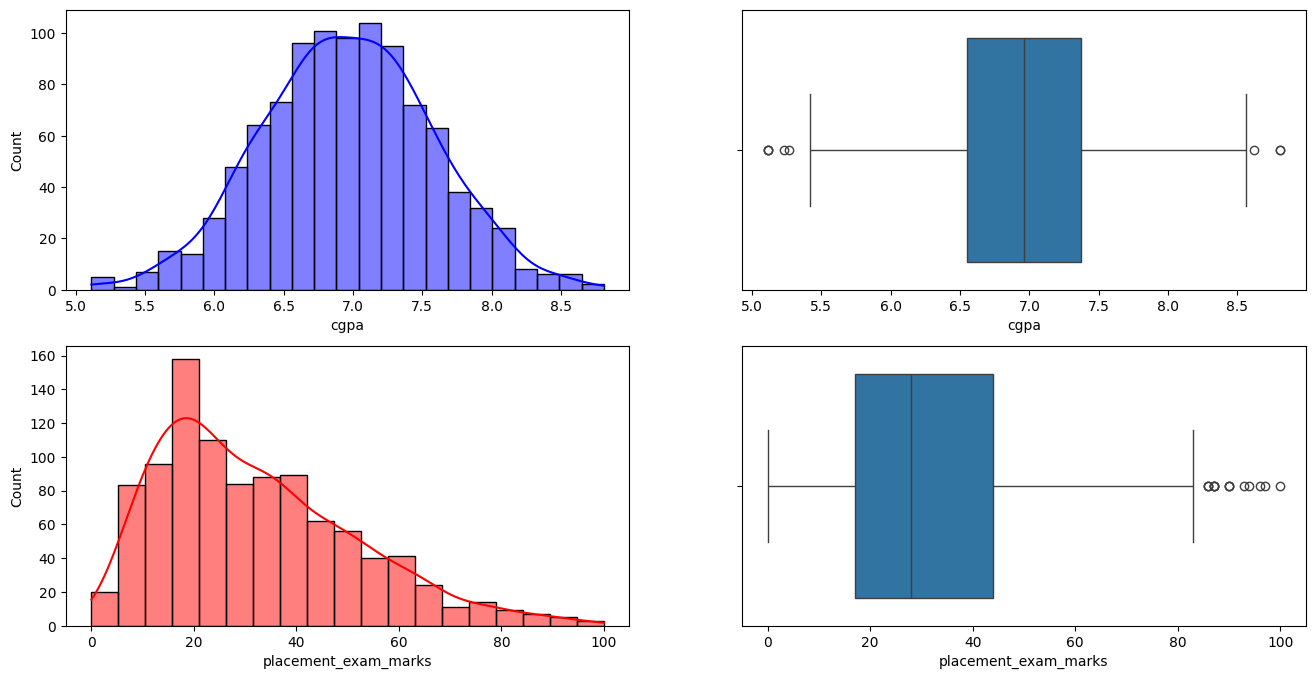

In [14]:
fig = plt.figure(figsize=(16, 8))

plt.subplot(2,2,1)
sns.histplot(df['cgpa'], kde=True, color='blue')

plt.subplot(2,2,2)
sns.boxplot(x=df['cgpa'])

plt.subplot(2,2,3)
sns.histplot(df['placement_exam_marks'], kde=True, color='red')

plt.subplot(2,2,4)
sns.boxplot(x=df['placement_exam_marks'])

plt.show()

In [5]:
df['placement_exam_marks'].skew()

np.float64(0.8356419499466834)

In [6]:
print('Mean value of CGPA:', df['cgpa'].mean())
print('Standard deviation of CGPA:', df['cgpa'].std())
print('Maximum value of CGPA:', df['cgpa'].max())
print('Minimum value of CGPA:', df['cgpa'].min())

Mean value of CGPA: 6.96124
Standard deviation of CGPA: 0.6158978751323896
Maximum value of CGPA: 9.12
Minimum value of CGPA: 4.89


In [7]:
# Finding boundary values
print('Highest allowed:', df['cgpa'].mean() + 3*df['cgpa'].std())
print('Lowest allowed:', df['cgpa'].mean() - 3*df['cgpa'].std())

Highest allowed: 8.808933625397168
Lowest allowed: 5.113546374602832


In [8]:
# Finding Outliers

df[(df['cgpa']>8.80)| (df['cgpa']<5.11)]

,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


## Trimming

In [16]:
new_df = df[(df['cgpa']<8.80) & (df['cgpa']>5.11)]
new_df

,cgpa,placement_exam_marks,placed
0,7.190000,26.0,1
1,7.460000,38.0,1
2,7.540000,40.0,1
3,6.420000,8.0,1
4,7.230000,17.0,0
...,...,...,...
993,6.730000,21.0,1
994,6.480000,63.0,0
997,5.113546,34.0,0
998,8.620000,46.0,1


In [23]:
fig = plt.figure(figsize=(16, 8))

plt.subplot(2,2,1)
sns.histplot(new_df['cgpa'], kde=True, color='blue')

plt.subplot(2,2,2)
sns.boxplot(x=new_df['cgpa'], color=)


plt.show()

SyntaxError: expected argument value expression (566106578.py, line 7)

## Capping

In [10]:
upper_limit = df['cgpa'].mean() + 3*df['cgpa'].std()
lower_limit = df['cgpa'].mean() - 3*df['cgpa'].std()

In [20]:
df['cgpa'] = np.where(
    df['cgpa']>upper_limit,
    upper_limit,
    np.where(
        df['cgpa']<lower_limit,
        lower_limit,
        df['cgpa']
    )
)

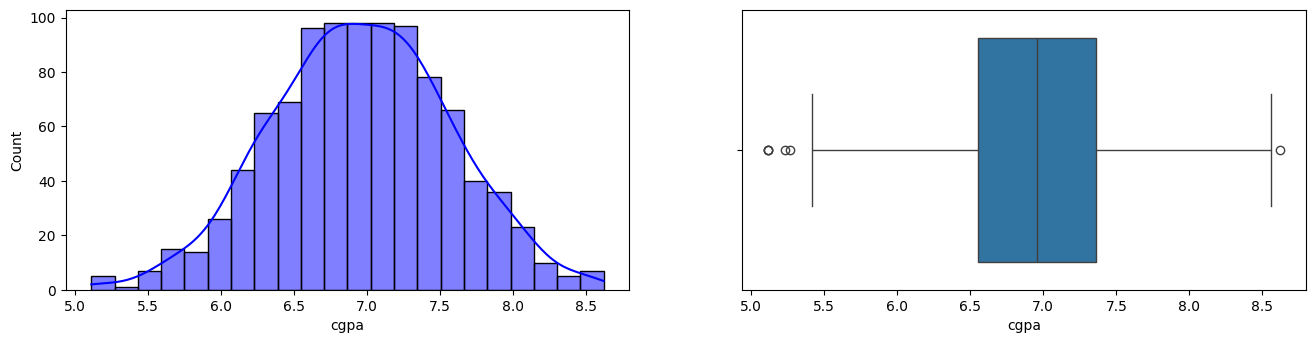

In [21]:
fig = plt.figure(figsize=(16, 8))

plt.subplot(2,2,1)
sns.histplot(new_df['cgpa'], kde=True, color='blue')

plt.subplot(2,2,2)
sns.boxplot(x=new_df['cgpa'])



plt.show()

In [12]:
df['cgpa'].describe()

count    1000.000000
mean        6.961499
std         0.612688
min         5.113546
25%         6.550000
50%         6.960000
75%         7.370000
max         8.808934
Name: cgpa, dtype: float64